# Taller de regresión lineal: ingreso mensual frente a la edad

**Autor:** Camilo Andrés Díaz García

**Asignatura:** Inteligencia Artificial, Universidad Sergio Arboleda, 2026

Este cuaderno ajusta un modelo de regresión lineal simple para predecir
el ingreso mensual a partir de la edad, con los datos del archivo
`data.xlsx`. El modelo tiene la forma

$$\hat{y} = m\,x + b$$

donde $x$ es la edad en años, $m$ es la pendiente, $b$ es el intercepto y
$\hat{y}$ es el ingreso mensual estimado. El entrenamiento y la
evaluación se ejecutan por completo en este cuaderno, y las figuras se
guardan en la carpeta `resultados`.

## 1. Configuración

Se importan las librerías y se fijan la semilla y la fracción de datos
reservada para la prueba. Con la semilla fija, la partición de los datos
y los resultados son reproducibles.

In [1]:
import os
import platform
import sys
import tracemalloc
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.ticker import FuncFormatter
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

try:
    import psutil
except ImportError:
    psutil = None

T_INICIO = perf_counter()
SEMILLA = 42
FRACCION_PRUEBA = 0.20
CARPETA_FIGURAS = Path("resultados")
CARPETA_FIGURAS.mkdir(exist_ok=True)

LIMITES_EDAD = [0, 20, 30, 40, 50, 60, 70, 120]
ETIQUETAS_EDAD = ["hasta 20", "21 a 30", "31 a 40", "41 a 50", "51 a 60",
                  "61 a 70", "más de 70"]

AZUL, NARANJA, GRIS, GRIS_CLARO = "#2a6f97", "#d9480f", "#5c6770", "#b8c1c8"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e3e6e8",
    "axes.titleweight": "bold",
    "figure.dpi": 110,
})


def numero(valor, decimales=0):
    """Formatea con punto de miles y coma decimal."""
    texto = f"{valor:,.{decimales}f}"
    return texto.replace(",", "#").replace(".", ",").replace("#", ".")


def miles(valor, _posicion=None):
    """Formateador de ejes con punto como separador de miles."""
    return numero(valor)


def guardar(figura, nombre):
    """Guarda la figura en la carpeta de resultados."""
    figura.savefig(CARPETA_FIGURAS / nombre, dpi=160, bbox_inches="tight")

## 2. Carga y revisión de los datos

En Google Colab se solicita el archivo `data.xlsx` mediante un cuadro de
carga. En un entorno local se lee desde la carpeta del cuaderno. Los
datos están en la primera hoja del libro.

In [2]:
try:
    from google.colab import files
    print("Seleccionar el archivo data.xlsx")
    ruta_datos = next(iter(files.upload()))
except ImportError:
    ruta_datos = "data.xlsx"

datos = pd.read_excel(ruta_datos, sheet_name=0)
datos = datos[["edad", "ingreso_mensual"]].dropna()
print(f"Registros disponibles: {numero(len(datos))}")

Registros disponibles: 10.280


In [3]:
resumen = datos.describe(percentiles=[0.25, 0.5, 0.75]).T
resumen.columns = ["conteo", "media", "desviación", "mínimo", "Q1",
                   "mediana", "Q3", "máximo"]
resumen.index = ["edad (años)", "ingreso mensual"]
resumen.round(1)

,conteo,media,desviación,mínimo,Q1,mediana,Q3,máximo
edad (años),10280.0,39.7,14.0,12.0,28.0,39.0,50.0,98.0
ingreso mensual,10280.0,7362.4,5897.3,1000.0,3870.0,6000.0,9000.0,81000.0


In [4]:
q1, q3 = datos["ingreso_mensual"].quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)
control = pd.DataFrame({
    "verificación": ["valores nulos",
                     "ingresos menores o iguales a cero",
                     "ingresos sobre el límite de atípicos (RIC)"],
    "registros": [int(datos.isna().sum().sum()),
                  int((datos["ingreso_mensual"] <= 0).sum()),
                  int((datos["ingreso_mensual"] > limite_superior).sum())],
})
print(f"Límite superior de atípicos: {numero(limite_superior)}")
control

Límite superior de atípicos: 16.695


,verificación,registros
0,valores nulos,0
1,ingresos menores o iguales a cero,0
2,ingresos sobre el límite de atípicos (RIC),573


Los registros atípicos se conservan: corresponden a ingresos altos
plausibles y el taller pide ajustar el modelo con los datos completos.

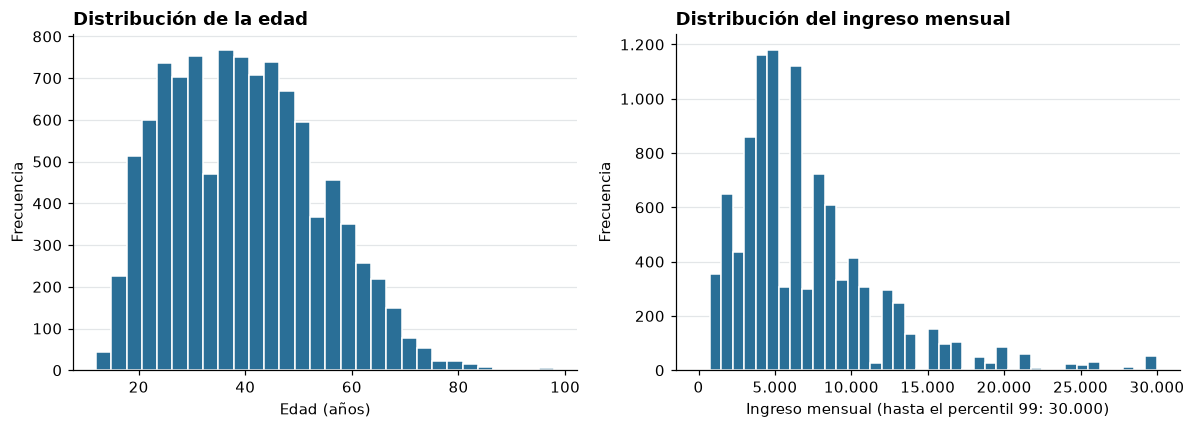

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].hist(datos["edad"], bins=30, color=AZUL, edgecolor="white")
ejes[0].set_title("Distribución de la edad", loc="left")
ejes[0].set_xlabel("Edad (años)")
ejes[0].set_ylabel("Frecuencia")
ejes[0].yaxis.set_major_formatter(FuncFormatter(miles))

techo = datos["ingreso_mensual"].quantile(0.99)
ejes[1].hist(datos["ingreso_mensual"], bins=40, range=(0, techo),
             color=AZUL, edgecolor="white")
ejes[1].set_title("Distribución del ingreso mensual", loc="left")
ejes[1].set_xlabel(f"Ingreso mensual (hasta el percentil 99: {numero(techo)})")
ejes[1].set_ylabel("Frecuencia")
ejes[1].xaxis.set_major_formatter(FuncFormatter(miles))
ejes[1].yaxis.set_major_formatter(FuncFormatter(miles))

fig.tight_layout()
guardar(fig, "fig_distribuciones.png")
plt.show()

## 3. Relación entre la edad y el ingreso

Antes de ajustar el modelo se mide la asociación lineal con el
coeficiente de Pearson y la asociación monótona con el de Spearman. Luego
se compara el ingreso por grupos de edad.

In [6]:
pearson = datos["edad"].corr(datos["ingreso_mensual"])
spearman = datos["edad"].corr(datos["ingreso_mensual"], method="spearman")
correlaciones = pd.DataFrame({
    "coeficiente": ["Pearson", "Spearman"],
    "valor": [round(pearson, 4), round(spearman, 4)],
})
correlaciones

,coeficiente,valor
0,Pearson,0.0382
1,Spearman,0.0249


In [7]:
grupos = pd.cut(datos["edad"], bins=LIMITES_EDAD, labels=ETIQUETAS_EDAD)
por_grupo = datos.groupby(grupos, observed=True)["ingreso_mensual"].agg(
    ["count", "mean", "median"])
por_grupo.columns = ["conteo", "media", "mediana"]
por_grupo.index.name = "grupo de edad"
por_grupo.round(0)

,conteo,media,mediana
grupo de edad,,,
hasta 20,783,4541.0,4300.0
21 a 30,2308,7180.0,6020.0
31 a 40,2472,8066.0,6450.0
41 a 50,2332,7916.0,6450.0
51 a 60,1555,7795.0,6020.0
61 a 70,655,6465.0,4500.0
más de 70,175,4587.0,3440.0


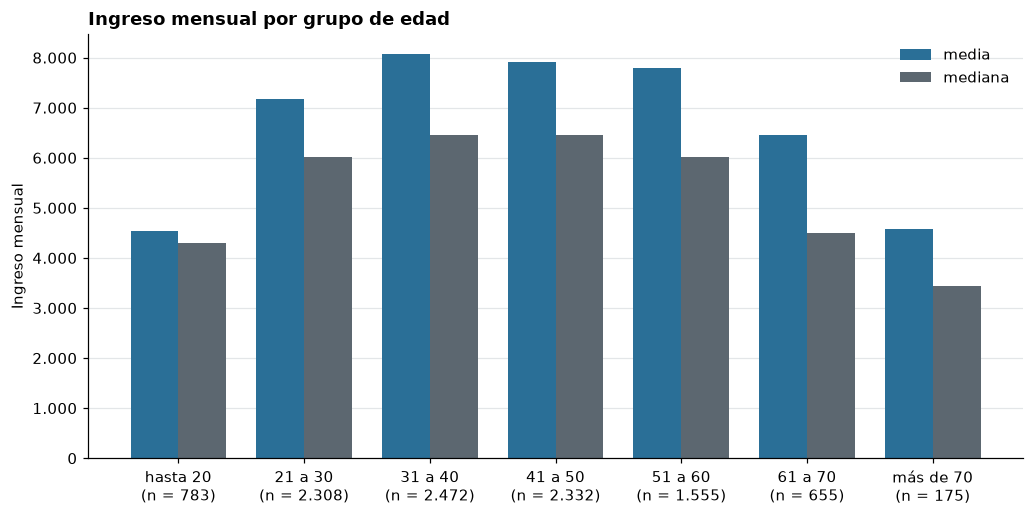

In [8]:
posicion = np.arange(len(por_grupo))
ancho = 0.38
fig, eje = plt.subplots(figsize=(9.5, 4.8))
eje.bar(posicion - ancho / 2, por_grupo["media"], ancho, color=AZUL,
        label="media")
eje.bar(posicion + ancho / 2, por_grupo["mediana"], ancho, color=GRIS,
        label="mediana")
eje.set_xticks(posicion)
eje.set_xticklabels([f"{grupo}\n(n = {numero(n)})"
                     for grupo, n in zip(por_grupo.index,
                                         por_grupo["conteo"])])
eje.yaxis.set_major_formatter(FuncFormatter(miles))
eje.set_ylabel("Ingreso mensual")
eje.set_title("Ingreso mensual por grupo de edad", loc="left")
eje.legend(frameon=False)
fig.tight_layout()
guardar(fig, "fig_grupos_edad.png")
plt.show()

## 4. Partición de los datos y entrenamiento

Los datos se dividen en un 80 % para entrenamiento y un 20 % para
prueba. La variable predictora es la edad y la variable objetivo es el
ingreso mensual. El modelo se entrena con `LinearRegression`, que
estima la pendiente $m$ y el intercepto $b$ por mínimos cuadrados
ordinarios.

In [9]:
X = datos[["edad"]]
y = datos["ingreso_mensual"]

X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=FRACCION_PRUEBA, random_state=SEMILLA)

print(f"Entrenamiento: {numero(len(X_entrenamiento))} registros")
print(f"Prueba: {numero(len(X_prueba))} registros")

Entrenamiento: 8.224 registros
Prueba: 2.056 registros


In [10]:
modelo = LinearRegression()
modelo.fit(X_entrenamiento, y_entrenamiento)

pendiente = modelo.coef_[0]
intercepto = modelo.intercept_
print(f"ingreso_mensual = {numero(pendiente, 2)} * edad "
      f"+ {numero(intercepto, 2)}")

ingreso_mensual = 16,07 * edad + 6.718,52


## 5. Evaluación

El modelo se evalúa con tres métricas: el coeficiente de determinación
$R^2$, el error absoluto medio (MAE) y la raíz del error cuadrático
medio (RMSE). Como referencia se usa un modelo que siempre predice la
media del ingreso de entrenamiento. Además, se ajusta un modelo con
término cuadrático $\hat{y} = a\,x^2 + m\,x + b$ solo
como contraste para revisar si el supuesto de linealidad es adecuado.

In [11]:
referencia = DummyRegressor(strategy="mean").fit(
    X_entrenamiento, y_entrenamiento)
cuadratico = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()).fit(X_entrenamiento, y_entrenamiento)


def evaluar(modelo_ajustado, X_datos, y_datos):
    """Calcula R², MAE y RMSE de un modelo sobre un conjunto."""
    predicho = modelo_ajustado.predict(X_datos)
    return {
        "R²": r2_score(y_datos, predicho),
        "MAE": mean_absolute_error(y_datos, predicho),
        "RMSE": np.sqrt(mean_squared_error(y_datos, predicho)),
    }


def predecir_ingreso(edades):
    """Devuelve el ingreso mensual estimado por el modelo lineal."""
    tabla = pd.DataFrame({"edad": edades})
    return modelo.predict(tabla)


metricas = pd.DataFrame({
    "Lineal (entrenamiento)": evaluar(modelo, X_entrenamiento,
                                      y_entrenamiento),
    "Lineal (prueba)": evaluar(modelo, X_prueba, y_prueba),
    "Cuadrático (prueba)": evaluar(cuadratico, X_prueba, y_prueba),
    "Referencia: media (prueba)": evaluar(referencia, X_prueba, y_prueba),
}).T
metricas.round(4)

,R²,MAE,RMSE
Lineal (entrenamiento),0.0014,3809.8392,5950.3496
Lineal (prueba),0.0015,3881.4499,5656.3083
Cuadrático (prueba),0.0280,3764.7360,5580.8263
Referencia: media (prueba),-0.0000,3882.9604,5660.6519


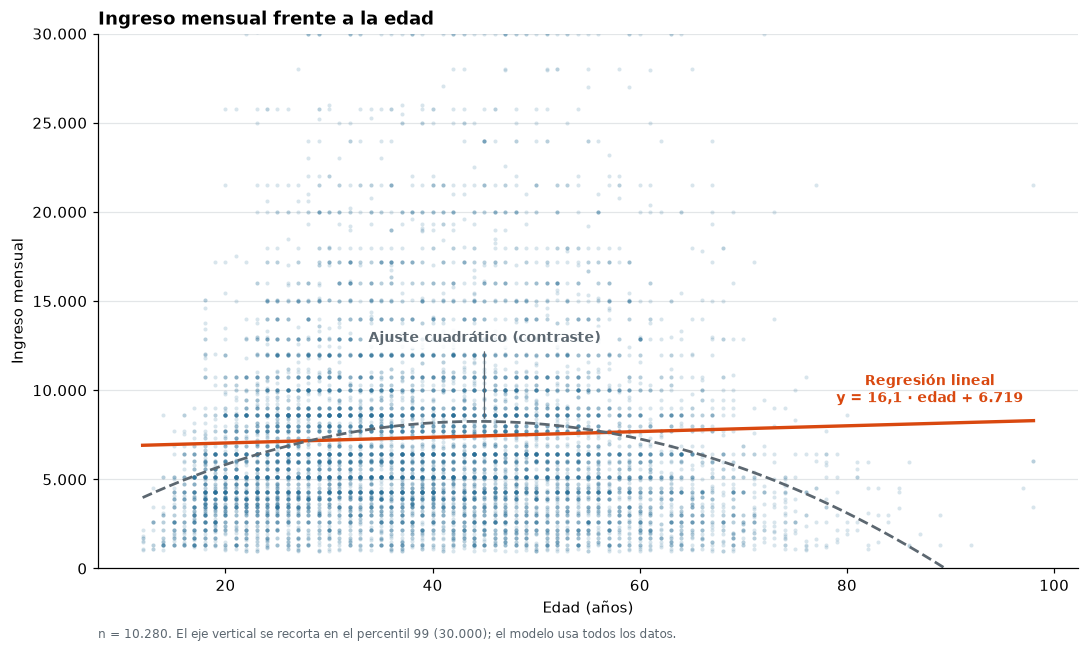

In [12]:
rango = pd.DataFrame({"edad": np.linspace(datos["edad"].min(),
                                          datos["edad"].max(), 200)})
fig, eje = plt.subplots(figsize=(10, 6))
eje.scatter(datos["edad"], datos["ingreso_mensual"], s=7, alpha=0.18,
            color=AZUL, linewidths=0)
eje.plot(rango["edad"], modelo.predict(rango), color=NARANJA, lw=2.2)
eje.plot(rango["edad"], cuadratico.predict(rango), color=GRIS, lw=1.8,
         ls="--")
eje.set_ylim(0, techo)
eje.yaxis.set_major_formatter(FuncFormatter(miles))
eje.set_xlabel("Edad (años)")
eje.set_ylabel("Ingreso mensual")
eje.set_title("Ingreso mensual frente a la edad", loc="left")

punto = pd.DataFrame({"edad": [88]})
eje.annotate(f"Regresión lineal\ny = {numero(pendiente, 1)} · edad"
             f" + {numero(intercepto)}",
             xy=(88, modelo.predict(punto)[0]), xytext=(0, 14),
             textcoords="offset points", color=NARANJA, fontsize=9,
             ha="center", fontweight="bold")
cima = pd.DataFrame({"edad": [45]})
eje.annotate("Ajuste cuadrático (contraste)",
             xy=(45, cuadratico.predict(cima)[0]), xytext=(0, 52),
             textcoords="offset points", color=GRIS, fontsize=9,
             ha="center", fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none",
                       alpha=0.85),
             arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.8))
eje.text(0, -0.13, f"n = {numero(len(datos))}. El eje vertical se recorta en "
         f"el percentil 99 ({numero(techo)}); el modelo usa todos los datos.",
         transform=eje.transAxes, fontsize=8, color=GRIS)
fig.tight_layout()
guardar(fig, "fig_regresion.png")
plt.show()

## 6. Análisis de residuales

El residual es la diferencia entre el ingreso real y el estimado por el
modelo lineal. Si el supuesto de linealidad fuera adecuado, los residuales
se distribuirían alrededor de cero sin un patrón según la edad.

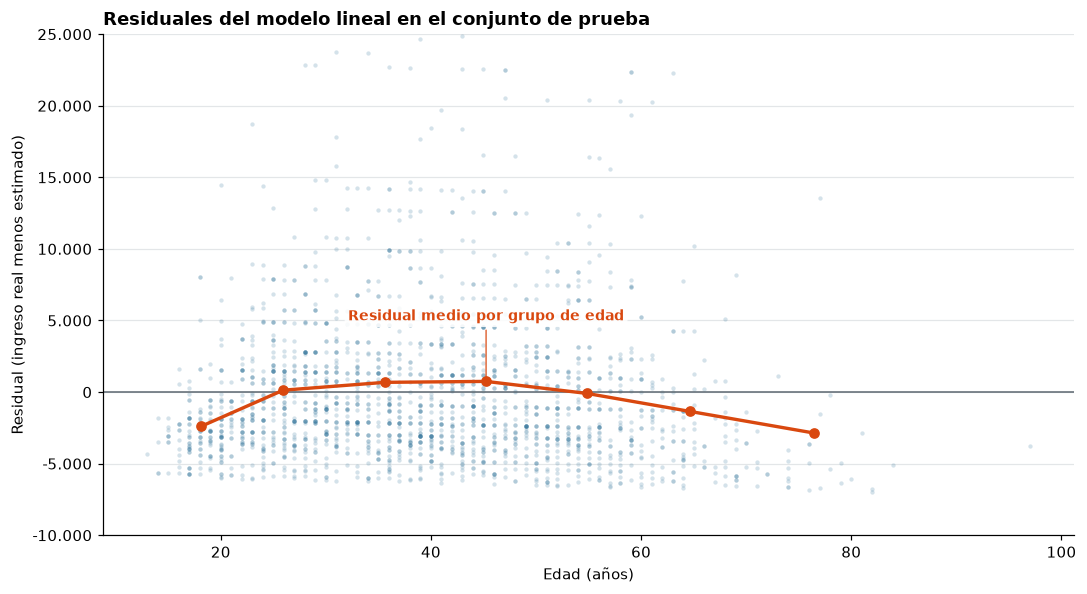

In [13]:
residuales = y_prueba - modelo.predict(X_prueba)
tabla_residuales = pd.DataFrame({
    "edad": X_prueba["edad"],
    "residual": residuales,
    "grupo": pd.cut(X_prueba["edad"], bins=LIMITES_EDAD,
                    labels=ETIQUETAS_EDAD),
})
medias = tabla_residuales.groupby("grupo", observed=True).mean()

fig, eje = plt.subplots(figsize=(10, 5.5))
eje.scatter(tabla_residuales["edad"], tabla_residuales["residual"], s=8,
            alpha=0.2, color=AZUL, linewidths=0)
eje.axhline(0, color=GRIS, lw=1)
eje.plot(medias["edad"], medias["residual"], color=NARANJA, lw=2.2,
         marker="o", ms=6)
eje.set_ylim(-10000, 25000)
eje.yaxis.set_major_formatter(FuncFormatter(miles))
eje.set_xlabel("Edad (años)")
eje.set_ylabel("Residual (ingreso real menos estimado)")
eje.set_title("Residuales del modelo lineal en el conjunto de prueba",
              loc="left")
eje.annotate("Residual medio por grupo de edad",
             xy=(medias["edad"].iloc[3], medias["residual"].iloc[3]),
             xytext=(0, 40), textcoords="offset points", color=NARANJA,
             fontsize=9, fontweight="bold", ha="center",
             bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none",
                       alpha=0.85),
             arrowprops=dict(arrowstyle="-", color=NARANJA, lw=0.8))
fig.tight_layout()
guardar(fig, "fig_residuales.png")
plt.show()

In [14]:
medias_grupo = medias["residual"].round(0).to_frame("residual medio")
medias_grupo.index.name = "grupo de edad"
medias_grupo

,residual medio
grupo de edad,
hasta 20,-2403.0
21 a 30,132.0
31 a 40,680.0
41 a 50,746.0
51 a 60,-96.0
61 a 70,-1348.0
más de 70,-2855.0


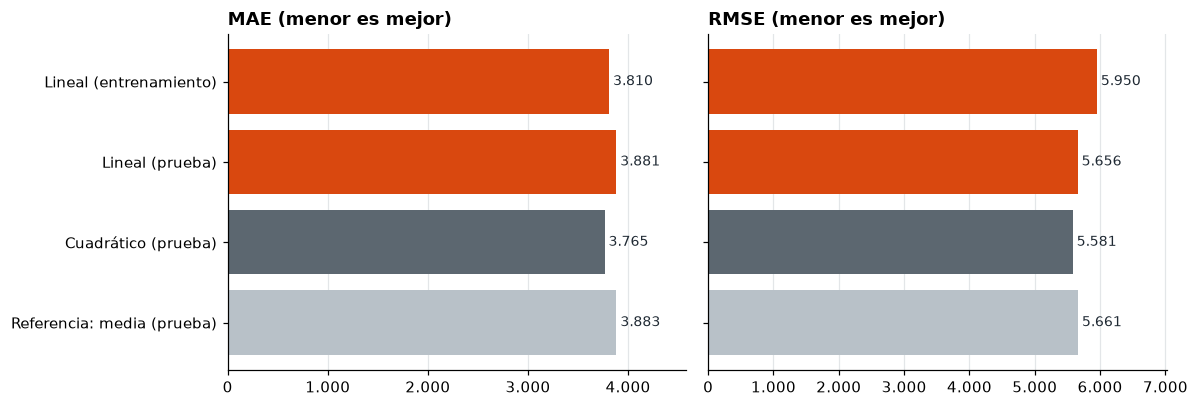

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
nombres = list(metricas.index)
colores = [NARANJA, NARANJA, GRIS, GRIS_CLARO]
filas = [1, 2, 3, 4]
for eje, metrica in zip(ejes, ["MAE", "RMSE"]):
    valores = metricas[metrica].values
    eje.barh(filas, valores, color=colores)
    eje.set_yticks(filas)
    eje.set_yticklabels(nombres if metrica == "MAE" else [])
    eje.invert_yaxis()
    eje.set_title(f"{metrica} (menor es mejor)", loc="left")
    eje.xaxis.set_major_formatter(FuncFormatter(miles))
    eje.grid(axis="x")
    eje.grid(axis="y", visible=False)
    for fila, valor in zip(filas, valores):
        eje.text(valor, fila, f" {numero(valor)}", va="center", fontsize=9,
                 color="#1f2933")
    eje.set_xlim(0, valores.max() * 1.18)
fig.tight_layout()
guardar(fig, "fig_errores.png")
plt.show()

## 7. Predicciones del ingreso mensual

Con el modelo entrenado se estima el ingreso mensual para edades dentro
del rango observado en los datos.

In [16]:
edades_consulta = [20, 25, 30, 35, 40, 45, 50, 55, 60, 65]
predicciones = pd.DataFrame({
    "edad": edades_consulta,
    "ingreso estimado (lineal)": predecir_ingreso(edades_consulta),
    "ingreso estimado (cuadrático)": cuadratico.predict(
        pd.DataFrame({"edad": edades_consulta})),
}).round(0).astype({"ingreso estimado (lineal)": int,
                    "ingreso estimado (cuadrático)": int})
predicciones

,edad,ingreso estimado (lineal),ingreso estimado (cuadrático)
0,20,7040,5826
1,25,7120,6718
2,30,7201,7406
3,35,7281,7891
4,40,7361,8173
5,45,7442,8251
6,50,7522,8127
7,55,7602,7799
8,60,7683,7268
9,65,7763,6534


## 8. Costo computacional

Se mide el tiempo de cada etapa, la memoria que usa el modelo y el peso de
los archivos del taller. Cada etapa se repite varias veces y se reporta el
promedio y la desviación estándar, porque un solo tiempo depende del estado
del equipo en ese instante. Los valores dependen del equipo donde se
ejecuta el cuaderno.

Con una sola variable predictora, `LinearRegression` resuelve los mínimos
cuadrados de un sistema con dos incógnitas (pendiente e intercepto). El
tiempo de entrenamiento y de predicción crece de forma lineal con el
número de registros $n$, y la memoria adicional es del orden de $n$ por el
número de variables.

In [17]:
def cronometrar(funcion, repeticiones):
    """Mide una función y devuelve el tiempo medio y la desviación en ms."""
    tiempos = []
    for _ in range(repeticiones):
        inicio = perf_counter()
        funcion()
        tiempos.append((perf_counter() - inicio) * 1000)
    return float(np.mean(tiempos)), float(np.std(tiempos))


etapas = [
    ("Lectura de data.xlsx", 5,
     lambda: pd.read_excel(ruta_datos, sheet_name=0)),
    ("Partición 80/20", 200,
     lambda: train_test_split(X, y, test_size=FRACCION_PRUEBA,
                              random_state=SEMILLA)),
    ("Entrenamiento lineal", 200,
     lambda: LinearRegression().fit(X_entrenamiento, y_entrenamiento)),
    ("Entrenamiento cuadrático", 200,
     lambda: make_pipeline(
         PolynomialFeatures(degree=2, include_bias=False),
         LinearRegression()).fit(X_entrenamiento, y_entrenamiento)),
    ("Predicción sobre la prueba", 200,
     lambda: modelo.predict(X_prueba)),
    ("Evaluación (R², MAE, RMSE)", 200,
     lambda: evaluar(modelo, X_prueba, y_prueba)),
]

filas_tiempo = []
for nombre_etapa, repeticiones, funcion in etapas:
    media_ms, desviacion_ms = cronometrar(funcion, repeticiones)
    filas_tiempo.append({"etapa": nombre_etapa,
                         "repeticiones": repeticiones,
                         "tiempo medio (ms)": media_ms,
                         "desviación (ms)": desviacion_ms})
tiempos = pd.DataFrame(filas_tiempo).set_index("etapa")
tiempos.round(3)

,repeticiones,tiempo medio (ms),desviación (ms)
etapa,,,
Lectura de data.xlsx,5,558.195,34.784
Partición 80/20,200,1.136,0.092
Entrenamiento lineal,200,1.355,0.089
Entrenamiento cuadrático,200,2.673,0.094
Predicción sobre la prueba,200,0.667,0.026
"Evaluación (R², MAE, RMSE)",200,2.292,0.135


In [18]:
tracemalloc.start()
LinearRegression().fit(X_entrenamiento, y_entrenamiento)
pico_ajuste = tracemalloc.get_traced_memory()[1]
tracemalloc.stop()

memoria_datos = datos.memory_usage(deep=True).sum()
print(f"Tabla de datos en memoria ({numero(len(datos))} filas): "
      f"{numero(memoria_datos / 1024, 1)} KiB")
print(f"Pico de memoria al ajustar el modelo lineal: "
      f"{numero(pico_ajuste / 1024, 1)} KiB")
if psutil is not None:
    memoria_proceso = psutil.Process().memory_info().rss
    print(f"Memoria del proceso de Python en este punto: "
          f"{numero(memoria_proceso / 2 ** 20, 1)} MiB")

Tabla de datos en memoria (10.280 filas): 160,8 KiB
Pico de memoria al ajustar el modelo lineal: 263,9 KiB
Memoria del proceso de Python en este punto: 240,6 MiB


In [19]:
archivos = [Path(ruta_datos)] + sorted(CARPETA_FIGURAS.glob("*.png"))
peso = pd.DataFrame({
    "archivo": [archivo.name for archivo in archivos],
    "peso (KiB)": [round(archivo.stat().st_size / 1024, 1)
                   for archivo in archivos],
}).set_index("archivo")
print(f"Peso total de los datos y las figuras: "
      f"{numero(peso['peso (KiB)'].sum(), 1)} KiB")
peso

Peso total de los datos y las figuras: 797,1 KiB


,peso (KiB)
archivo,
data.xlsx,362.2
fig_distribuciones.png,52.0
fig_errores.png,45.4
fig_grupos_edad.png,46.7
fig_regresion.png,185.5
fig_residuales.png,105.3


In [20]:
print(f"Sistema: {platform.platform()}")
print(f"Procesadores lógicos: {os.cpu_count()}")
if psutil is not None:
    ram_total = psutil.virtual_memory().total
    print(f"Memoria RAM total: {numero(ram_total / 2 ** 30, 1)} GiB")
print(f"Python {sys.version.split()[0]}, NumPy {np.__version__}, "
      f"pandas {pd.__version__}, scikit-learn {sklearn.__version__}")
print(f"Tiempo transcurrido desde el inicio del cuaderno: "
      f"{numero(perf_counter() - T_INICIO, 1)} s")

Sistema: Windows-11-10.0.26300-SP0
Procesadores lógicos: 12
Memoria RAM total: 15,9 GiB
Python 3.14.3, NumPy 2.5.2, pandas 3.0.5, scikit-learn 1.9.0
Tiempo transcurrido desde el inicio del cuaderno: 7,7 s


## 9. Conclusiones

- **Modelo ajustado.** La recta obtenida es
  $\hat{y} = 16{,}07\,x + 6.718{,}52$. Cada año adicional de edad se
  asocia con 16,07 unidades más de ingreso mensual, es decir, unas 161
  unidades por década.
- **Capacidad predictiva.** En el conjunto de prueba el $R^2$ es 0,0015:
  la edad explica el 0,15 % de la variación del ingreso. El MAE es 3.881
  frente a 3.883 del modelo que siempre predice la media, de modo que la
  recta no mejora la predicción de referencia.
- **Generalización.** El $R^2$ de entrenamiento (0,0014) y el de prueba
  (0,0015) son casi iguales. El bajo desempeño no se debe al
  sobreajuste, sino a que la edad, por sí sola y con una relación
  lineal, aporta muy poca información sobre el ingreso.
- **Forma de la relación.** El ingreso medio sube de 4.541 en el grupo de
  hasta 20 años a 8.066 en el de 31 a 40, se mantiene cerca de 7.900 y
  7.800 hasta los 60 y baja a 6.465 y 4.587 en los dos grupos
  siguientes. Los residuales medios reflejan ese patrón: son negativos
  en el grupo de hasta 20 años (-2.403) y en el de más de 70 (-2.855), y
  positivos entre los 21 y los 50 años. Una recta no puede representar
  una relación con forma de U invertida.
- **Modelo de contraste.** El término cuadrático eleva el $R^2$ a 0,0280
  y reduce el MAE a 3.765. La mejora confirma que la linealidad es una
  limitación, pero el 97 % de la variación sigue sin explicarse.
- **Predicciones.** El modelo lineal estima 7.040 a los 20 años y 7.763 a
  los 65, una diferencia de solo 723 en 45 años. Estas estimaciones
  sobrestiman el ingreso de las personas más jóvenes y de las mayores, y
  deben interpretarse como una tendencia promedio, no como un valor
  individual.
- **Alcance.** El archivo incluye otras variables (nivel educativo, años
  de escolaridad y sexo) que no se usaron, porque el taller solicita la
  relación entre ingreso y edad. Su aporte no se evaluó.
- **Costo computacional.** El entrenamiento, la predicción y la evaluación
  del modelo lineal toman milisegundos y su memoria es de unos pocos
  cientos de KiB. La etapa más lenta es la lectura del archivo Excel. Los
  valores medidos están en la sección 8.